In [2]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 1.9 MB/s eta 0:00:06
   -- ------------------------------------- 0.8/11.3 MB 2.3 MB/s eta 0:00:05
   ---- ----------------------------------- 1.3/11.3 MB 1.7 MB/s eta 0:00:06
   ----- ---------------------------------- 1.6/11.3 MB 1.8 MB/s eta 0:00:06
   ------ --------------------------------- 1.8/11.3 MB 1.6 MB/s eta 0:00:06
   ------ --------------------------------- 1.8/11.3 MB 1.6 MB/s eta 0:00:06
   ------- -------------------------------- 2.1/11.3 MB 1.5 MB/s eta 0:00:07
   --------- ------------------------------ 2.6/11.3 MB 1.5 MB/s eta 0:00:06
   --------- ------------------------------ 2.6/11.3 MB 1.5 MB/s eta 0:00:06
   ------------ --------------------------- 3.4/11.3 MB 1.5 MB/s eta 0:00:06
   ------------ ----


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Time Series Analysis libraries
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Load original dataset
data_path = Path("../data/raw/train.csv")

df = pd.read_csv(data_path, parse_dates=["date"])

print("Original dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Original dataset loaded successfully!
Dataset Shape: (913000, 4)


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [4]:
# Aggregate sales across all stores and items by date

daily_sales = df.groupby("date")["sales"].sum().reset_index()

# Sort data by date
daily_sales = daily_sales.sort_values("date")

# Set date as index
daily_sales.set_index("date", inplace=True)

# Display results
print("Daily sales aggregation completed!")
print("Aggregated Dataset Shape:", daily_sales.shape)

display(daily_sales.head())

Daily sales aggregation completed!
Aggregated Dataset Shape: (1826, 1)


C:\Users\aditi\AppData\Local\Temp\ipykernel_29616\4025660283.py:9: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  daily_sales.set_index("date", inplace=True)


,sales
date,
2013-01-01,13696
2013-01-02,13678
2013-01-03,14488
2013-01-04,15677
2013-01-05,16237


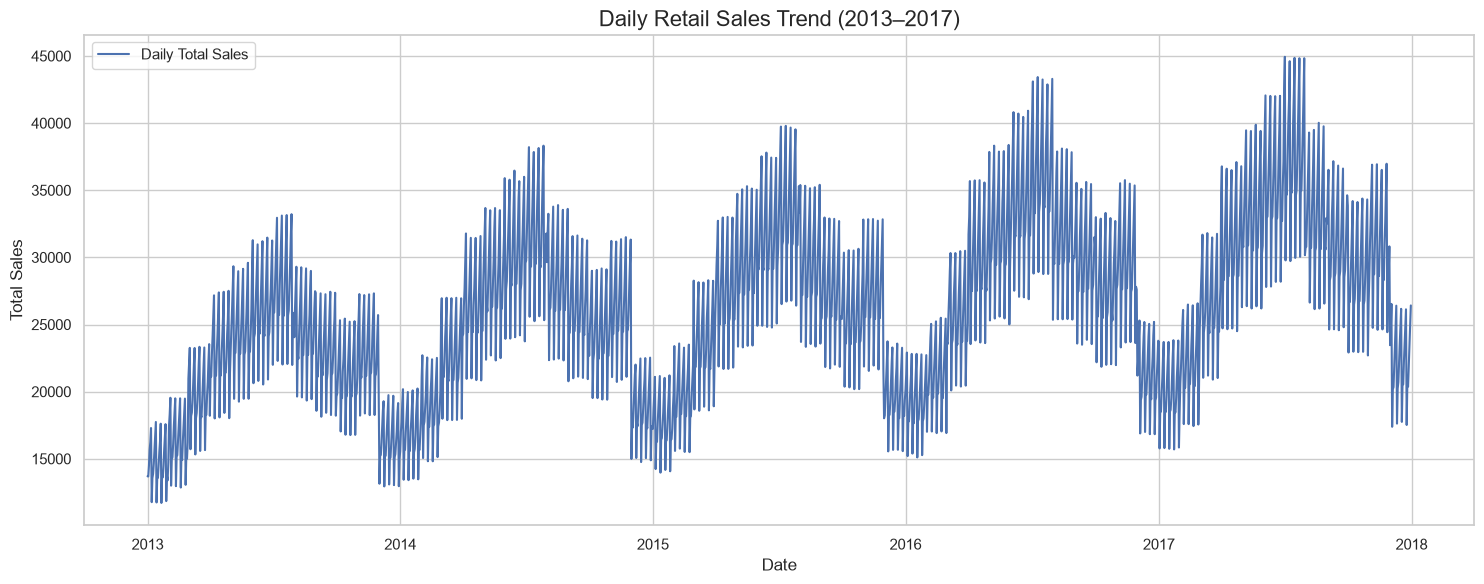

In [5]:
# Plot daily sales trend

plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales.index,
    daily_sales["sales"],
    label="Daily Total Sales"
)

plt.title("Daily Retail Sales Trend (2013–2017)", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [6]:
# Perform Augmented Dickey-Fuller (ADF) Test

adf_result = adfuller(daily_sales["sales"])

print("ADF Test Results")
print("--------------------------")
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Number of Lags:", adf_result[2])
print("Number of Observations:", adf_result[3])

print("\nCritical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")

# Interpret the result

if adf_result[1] <= 0.05:
    print("\nThe time series is STATIONARY.")
else:
    print("\nThe time series is NON-STATIONARY.")

ADF Test Results
--------------------------
ADF Statistic: -3.060244118701338
p-value: 0.029638649268844394
Number of Lags: 21
Number of Observations: 1804

Critical Values:
1%: -3.4339800605797155
5%: -2.8631434696839992
10%: -2.5676236347535166

The time series is STATIONARY.


C:\Users\aditi\AppData\Local\Temp\ipykernel_29616\2726356454.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(daily_sales["sales"])


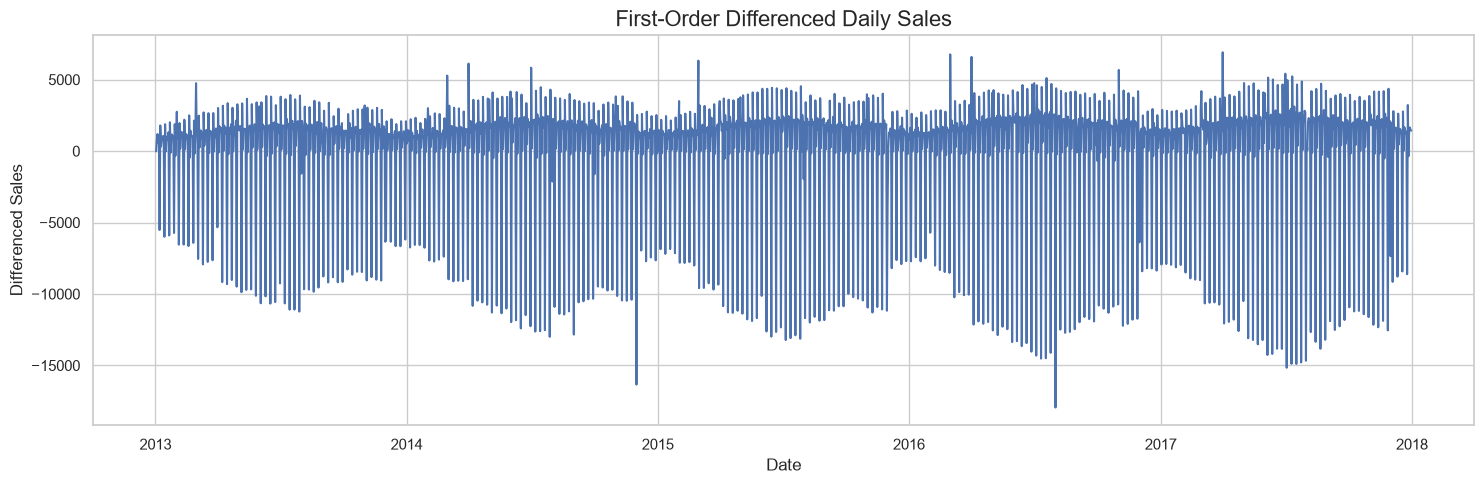

In [7]:
# Apply first-order differencing

daily_sales["sales_diff"] = daily_sales["sales"].diff()

# Remove the first NaN value
daily_sales["sales_diff"] = daily_sales["sales_diff"].dropna()

# Plot differenced series

plt.figure(figsize=(15, 5))

plt.plot(daily_sales.index, daily_sales["sales_diff"])

plt.title("First-Order Differenced Daily Sales", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Differenced Sales")
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
# Perform ADF test on first-order differenced data

differenced_data = daily_sales["sales_diff"].dropna()

adf_diff_result = adfuller(differenced_data)

print("ADF Test After First-Order Differencing")
print("----------------------------------------")
print("ADF Statistic:", adf_diff_result[0])
print("p-value:", adf_diff_result[1])
print("Number of Lags:", adf_diff_result[2])
print("Number of Observations:", adf_diff_result[3])

print("\nCritical Values:")

for key, value in adf_diff_result[4].items():
    print(f"{key}: {value}")

if adf_diff_result[1] <= 0.05:
    print("\nDifferenced series is STATIONARY.")
else:
    print("\nDifferenced series is NON-STATIONARY.")

ADF Test After First-Order Differencing
----------------------------------------
ADF Statistic: -8.919026559804946
p-value: 1.0533756813422718e-14
Number of Lags: 25
Number of Observations: 1799

Critical Values:
1%: -3.433990164137254
5%: -2.8631479299063405
10%: -2.567626009684832

Differenced series is STATIONARY.


C:\Users\aditi\AppData\Local\Temp\ipykernel_29616\384243492.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_result = adfuller(differenced_data)


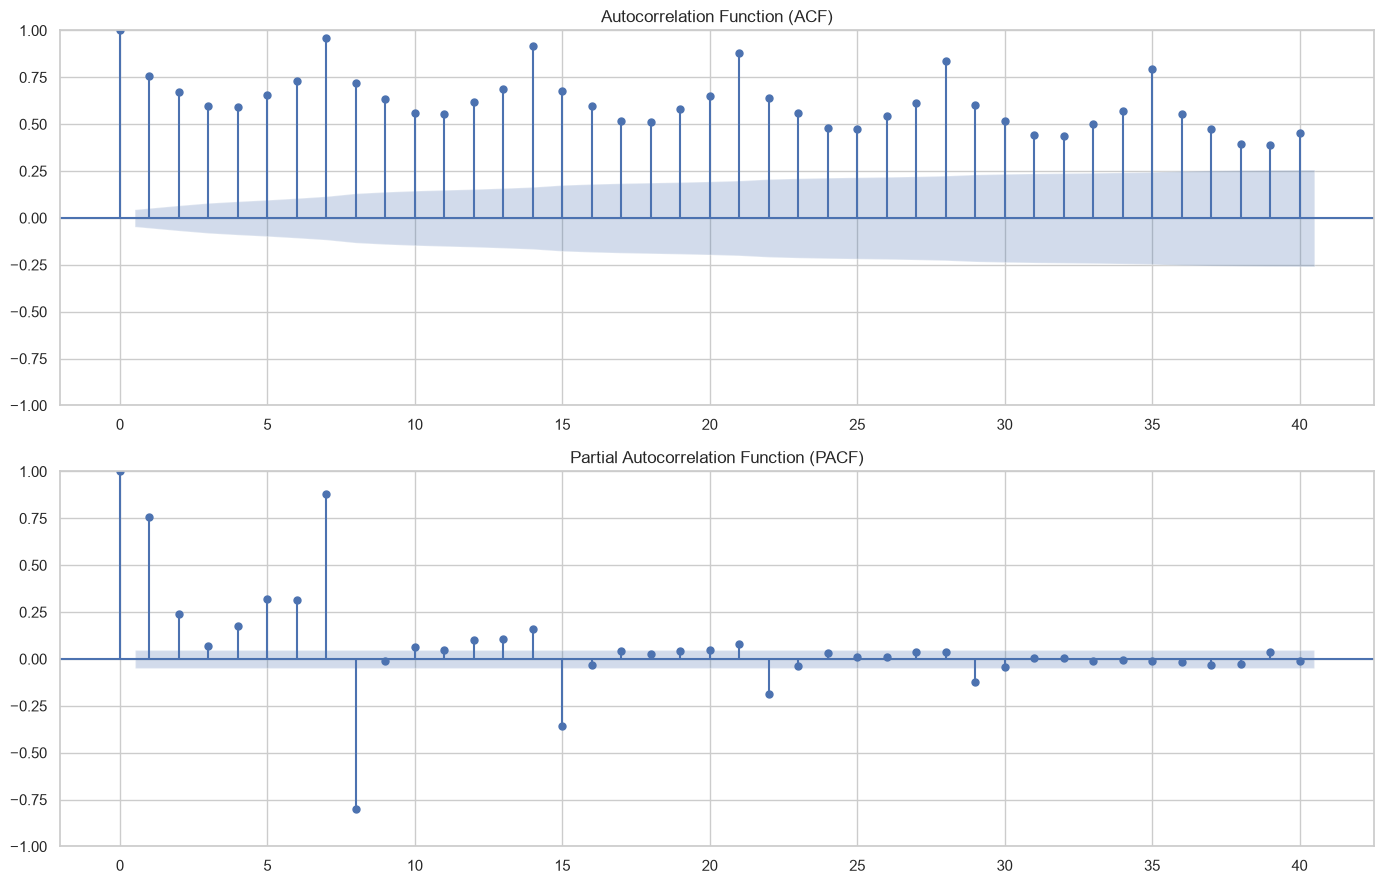

In [9]:
# Plot ACF and PACF

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# ACF plot
plot_acf(
    daily_sales["sales"],
    lags=40,
    ax=axes[0]
)

axes[0].set_title("Autocorrelation Function (ACF)")

# PACF plot
plot_pacf(
    daily_sales["sales"],
    lags=40,
    ax=axes[1],
    method="ywm"
)

axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

In [10]:
# Split data chronologically

train = daily_sales.loc["2013-01-01":"2016-12-31", "sales"]

test = daily_sales.loc["2017-01-01":"2017-12-31", "sales"]

# Display dataset information

print("Training and Testing Data Split")
print("--------------------------------")

print("Training Period:", train.index.min(), "to", train.index.max())
print("Testing Period:", test.index.min(), "to", test.index.max())

print("\nTraining Samples:", len(train))
print("Testing Samples:", len(test))

Training and Testing Data Split
--------------------------------
Training Period: 2013-01-01 00:00:00 to 2016-12-31 00:00:00
Testing Period: 2017-01-01 00:00:00 to 2017-12-31 00:00:00

Training Samples: 1461
Testing Samples: 365


In [11]:
# Build ARIMA model

arima_model = ARIMA(
    train,
    order=(1, 0, 1)
)

# Fit the model
arima_result = arima_model.fit()

# Display model summary
print(arima_result.summary())

c:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                 1461
Model:                 ARIMA(1, 0, 1)   Log Likelihood              -14050.491
Date:                Tue, 03 Nov 2026   AIC                          28108.982
Time:                        14:22:00   BIC                          28130.129
Sample:                    01-01-2013   HQIC                         28116.870
                         - 12-31-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        2.53e+04   2582.330      9.799      0.000    2.02e+04    3.04e+04
ar.L1          0.9960      0.003    396.993      0.000       0.991       1.001
ma.L1         -0.8628      0.013    -64.780      0.0

In [12]:
# Generate ARIMA forecasts for the test period

arima_forecast = arima_result.forecast(steps=len(test))

# Assign test dates to predictions
arima_forecast.index = test.index

# Display first 10 predictions

print("ARIMA Forecasts (First 10 Days)")
print("--------------------------------")

display(arima_forecast.head(10))

ARIMA Forecasts (First 10 Days)
--------------------------------


date
2017-01-01    21666.836421
2017-01-02    21681.240492
2017-01-03    21695.587519
2017-01-04    21709.877729
2017-01-05    21724.111346
2017-01-06    21738.288596
2017-01-07    21752.409700
2017-01-08    21766.474882
2017-01-09    21780.484363
2017-01-10    21794.438364
Name: predicted_mean, dtype: float64

In [13]:
# Evaluate ARIMA model

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate evaluation metrics
arima_mae = mean_absolute_error(test, arima_forecast)

arima_rmse = np.sqrt(
    mean_squared_error(test, arima_forecast)
)

# Display results
print("ARIMA Model Evaluation")
print("----------------------------")
print("MAE:", round(arima_mae, 2))
print("RMSE:", round(arima_rmse, 2))

ARIMA Model Evaluation
----------------------------
MAE: 7081.88
RMSE: 8700.9


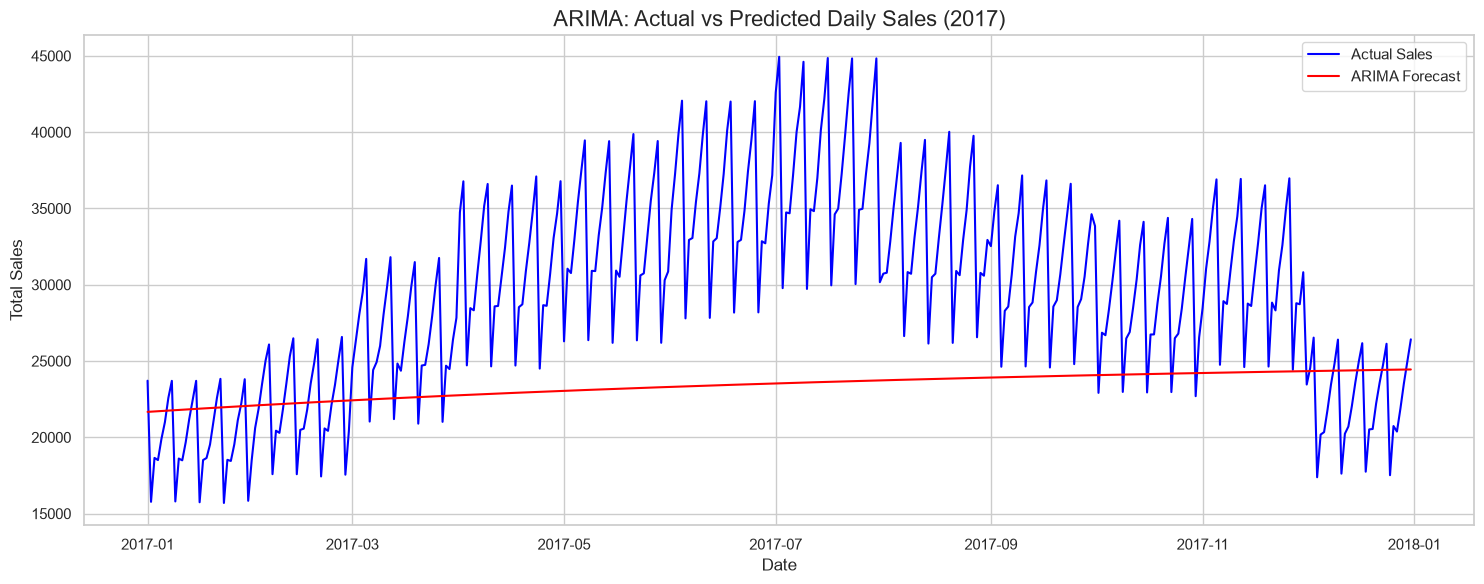

In [14]:
# Visualize actual vs predicted sales

plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test,
    label="Actual Sales",
    color="blue"
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast",
    color="red"
)

plt.title("ARIMA: Actual vs Predicted Daily Sales (2017)", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [15]:
# Build SARIMA model with weekly seasonality

sarima_model = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Fit the model
sarima_result = sarima_model.fit(disp=False)

# Display model summary
print(sarima_result.summary())

c:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                     
Dep. Variable:                             sales   No. Observations:                 1461
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 7)   Log Likelihood              -11708.921
Date:                           Tue, 03 Nov 2026   AIC                          23427.843
Time:                                   14:25:51   BIC                          23454.246
Sample:                               01-01-2013   HQIC                         23437.695
                                    - 12-31-2016                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9368      0.009    110.043      0.000       0.920       0.954
ma.L1         -0.0733      0.022     -3.284

c:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [16]:
# Generate SARIMA forecasts for the test period

sarima_forecast = sarima_result.forecast(steps=len(test))

# Assign test dates to predictions
sarima_forecast.index = test.index

# Display first 10 predictions

print("SARIMA Forecasts (First 10 Days)")
print("---------------------------------")

display(sarima_forecast.head(10))

SARIMA Forecasts (First 10 Days)
---------------------------------


date
2017-01-01    25066.412214
2017-01-02    16436.288747
2017-01-03    19359.572196
2017-01-04    19456.176828
2017-01-05    20760.577172
2017-01-06    22121.231699
2017-01-07    23718.125777
2017-01-08    24985.366276
2017-01-09    16370.974431
2017-01-10    19292.416867
Name: predicted_mean, dtype: float64

In [17]:
# Evaluate SARIMA model

sarima_mae = mean_absolute_error(test, sarima_forecast)

sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_forecast)
)

print("SARIMA Model Evaluation")
print("----------------------------")
print("MAE:", round(sarima_mae, 2))
print("RMSE:", round(sarima_rmse, 2))

SARIMA Model Evaluation
----------------------------
MAE: 9440.65
RMSE: 10868.49


In [18]:
# Compare ARIMA and SARIMA performance

model_comparison = pd.DataFrame({
    "Model": ["ARIMA", "SARIMA"],
    "MAE": [arima_mae, sarima_mae],
    "RMSE": [arima_rmse, sarima_rmse]
})

display(model_comparison)

# Identify the model with lower RMSE
best_model = model_comparison.loc[
    model_comparison["RMSE"].idxmin(), "Model"
]

print("Best Model based on RMSE:", best_model)

,Model,MAE,RMSE
0,ARIMA,7081.880241,8700.902409
1,SARIMA,9440.648890,10868.494514


Best Model based on RMSE: ARIMA


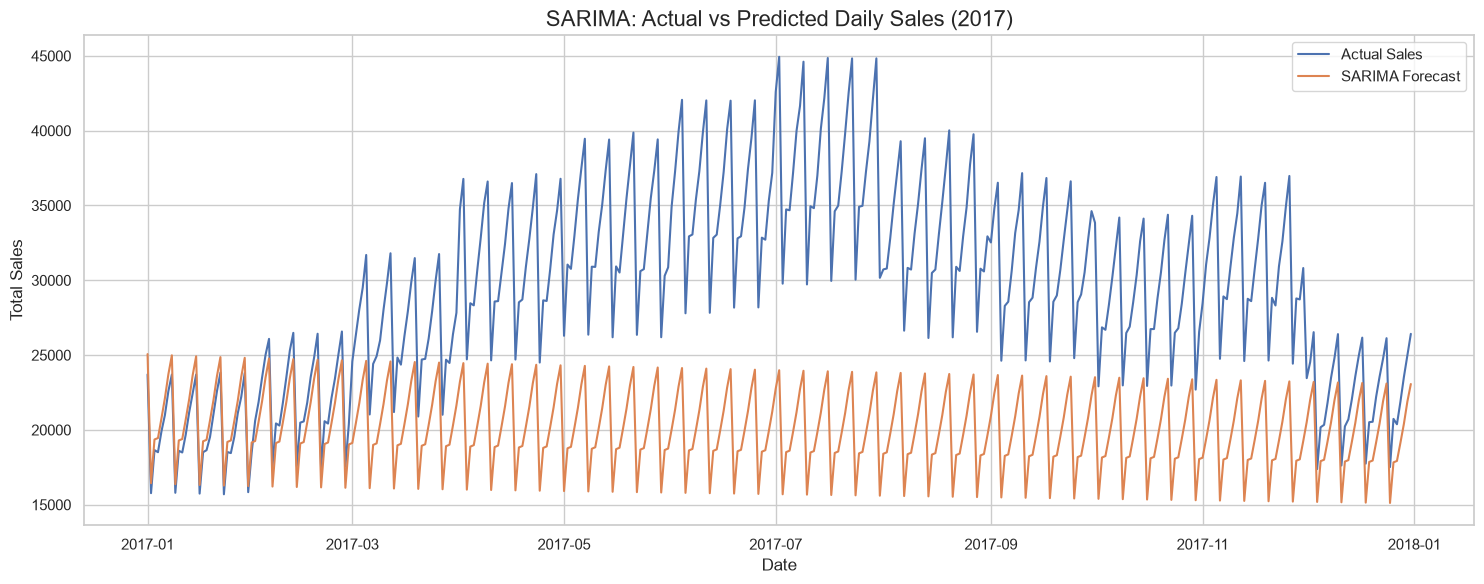

In [19]:
# Visualize actual vs predicted sales using SARIMA

plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test,
    label="Actual Sales"
)

plt.plot(
    sarima_forecast.index,
    sarima_forecast,
    label="SARIMA Forecast"
)

plt.title("SARIMA: Actual vs Predicted Daily Sales (2017)", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [20]:
# Evaluate SARIMA over a shorter 30-day forecasting horizon

short_test = test.iloc[:30]

short_sarima_forecast = sarima_result.forecast(steps=30)
short_sarima_forecast.index = short_test.index

short_mae = mean_absolute_error(
    short_test,
    short_sarima_forecast
)

short_rmse = np.sqrt(
    mean_squared_error(
        short_test,
        short_sarima_forecast
    )
)

print("SARIMA 30-Day Forecast Evaluation")
print("----------------------------------")
print("MAE:", round(short_mae, 2))
print("RMSE:", round(short_rmse, 2))

SARIMA 30-Day Forecast Evaluation
----------------------------------
MAE: 913.91
RMSE: 946.31


In [21]:
# Generate ARIMA forecast for the first 30 days

short_arima_forecast = arima_result.forecast(steps=30)
short_arima_forecast.index = short_test.index

# Calculate evaluation metrics

short_arima_mae = mean_absolute_error(
    short_test,
    short_arima_forecast
)

short_arima_rmse = np.sqrt(
    mean_squared_error(
        short_test,
        short_arima_forecast
    )
)

# Compare both models

short_model_comparison = pd.DataFrame({
    "Model": ["ARIMA", "SARIMA"],
    "MAE": [short_arima_mae, short_mae],
    "RMSE": [short_arima_rmse, short_rmse]
})

display(short_model_comparison)

,Model,MAE,RMSE
0,ARIMA,2686.680493,3242.221237
1,SARIMA,913.913570,946.312688


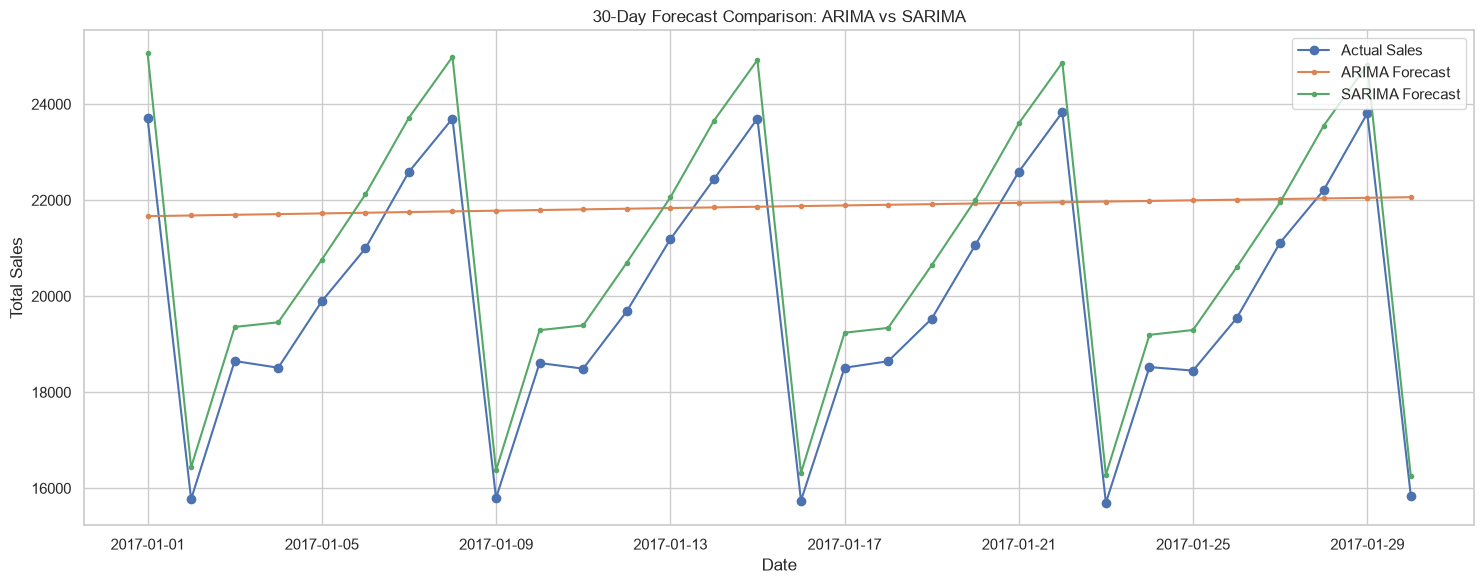

In [22]:
# Compare actual sales with 30-day forecasts

plt.figure(figsize=(15, 6))

plt.plot(
    short_test.index,
    short_test,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    short_arima_forecast.index,
    short_arima_forecast,
    label="ARIMA Forecast",
    marker="."
)

plt.plot(
    short_sarima_forecast.index,
    short_sarima_forecast,
    label="SARIMA Forecast",
    marker="."
)

plt.title("30-Day Forecast Comparison: ARIMA vs SARIMA")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

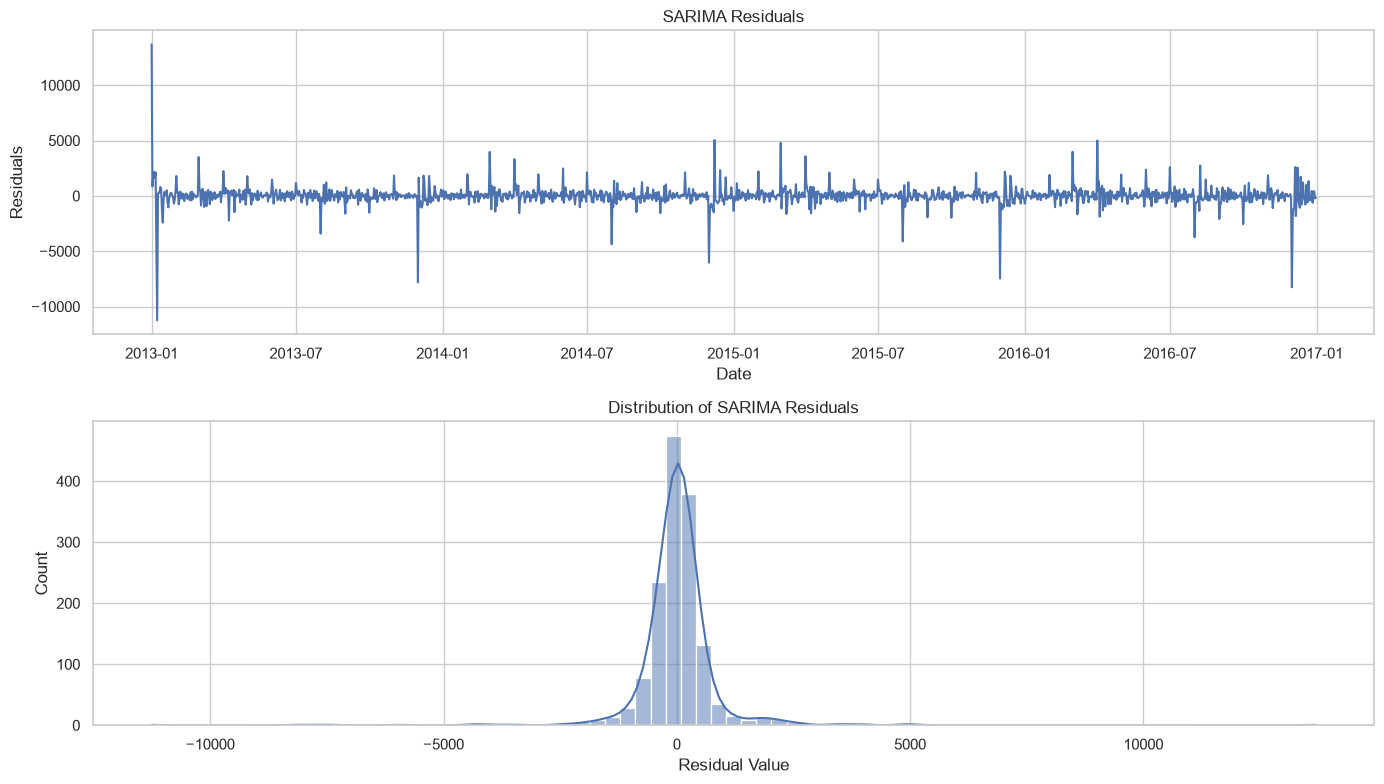

In [23]:
# Extract SARIMA residuals

sarima_residuals = sarima_result.resid

# Plot residuals and their distribution

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Residual plot
axes[0].plot(sarima_residuals)
axes[0].set_title("SARIMA Residuals")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Residuals")
axes[0].grid(True)

# Residual distribution
sns.histplot(
    sarima_residuals,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of SARIMA Residuals")
axes[1].set_xlabel("Residual Value")

plt.tight_layout()
plt.show()

In [24]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Ljung-Box test on SARIMA residuals

ljung_box_result = acorr_ljungbox(
    sarima_residuals,
    lags=[7, 14, 21, 28],
    return_df=True
)

print("Ljung-Box Test Results")
print("----------------------")

display(ljung_box_result)

Ljung-Box Test Results
----------------------


,lb_stat,lb_pvalue
7,32.506078,0.000033
14,34.407350,0.001798
21,36.451657,0.019443
28,42.782889,0.036523


In [25]:
# Build an improved SARIMA model with seasonal differencing

improved_sarima = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

improved_sarima_result = improved_sarima.fit(
    disp=False,
    maxiter=200
)

print("Improved SARIMA Model Results")
print("-----------------------------")

print(improved_sarima_result.summary())

c:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\aditi\OneDrive\Desktop\Retail-Sales-Demand-Forecasting-System\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Improved SARIMA Model Results
-----------------------------
                                     SARIMAX Results                                     
Dep. Variable:                             sales   No. Observations:                 1461
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 7)   Log Likelihood              -11647.271
Date:                           Tue, 03 Nov 2026   AIC                          23304.541
Time:                                   14:38:37   BIC                          23330.921
Sample:                               01-01-2013   HQIC                         23314.387
                                    - 12-31-2016                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9390      0.008    111.541      0.000       0

In [26]:
# Generate improved SARIMA forecasts for 2017

improved_sarima_forecast = improved_sarima_result.get_forecast(
    steps=len(test)
)

improved_sarima_predictions = improved_sarima_forecast.predicted_mean

improved_sarima_predictions.index = test.index

# Calculate evaluation metrics

improved_sarima_mae = mean_absolute_error(
    test,
    improved_sarima_predictions
)

improved_sarima_rmse = np.sqrt(
    mean_squared_error(
        test,
        improved_sarima_predictions
    )
)

print("Improved SARIMA Model Evaluation")
print("--------------------------------")
print("MAE:", round(improved_sarima_mae, 2))
print("RMSE:", round(improved_sarima_rmse, 2))

Improved SARIMA Model Evaluation
--------------------------------
MAE: 8749.1
RMSE: 10202.67


In [27]:
# Compare all forecasting models

final_model_comparison = pd.DataFrame({
    "Model": [
        "ARIMA",
        "Original SARIMA",
        "Improved SARIMA"
    ],
    "MAE": [
        arima_mae,
        sarima_mae,
        improved_sarima_mae
    ],
    "RMSE": [
        arima_rmse,
        sarima_rmse,
        improved_sarima_rmse
    ]
})

final_model_comparison = final_model_comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(final_model_comparison)

print(
    "Best model based on RMSE:",
    final_model_comparison.loc[0, "Model"]
)

,Model,MAE,RMSE
0,ARIMA,7081.880241,8700.902409
1,Improved SARIMA,8749.096507,10202.666457
2,Original SARIMA,9440.648890,10868.494514


Best model based on RMSE: ARIMA


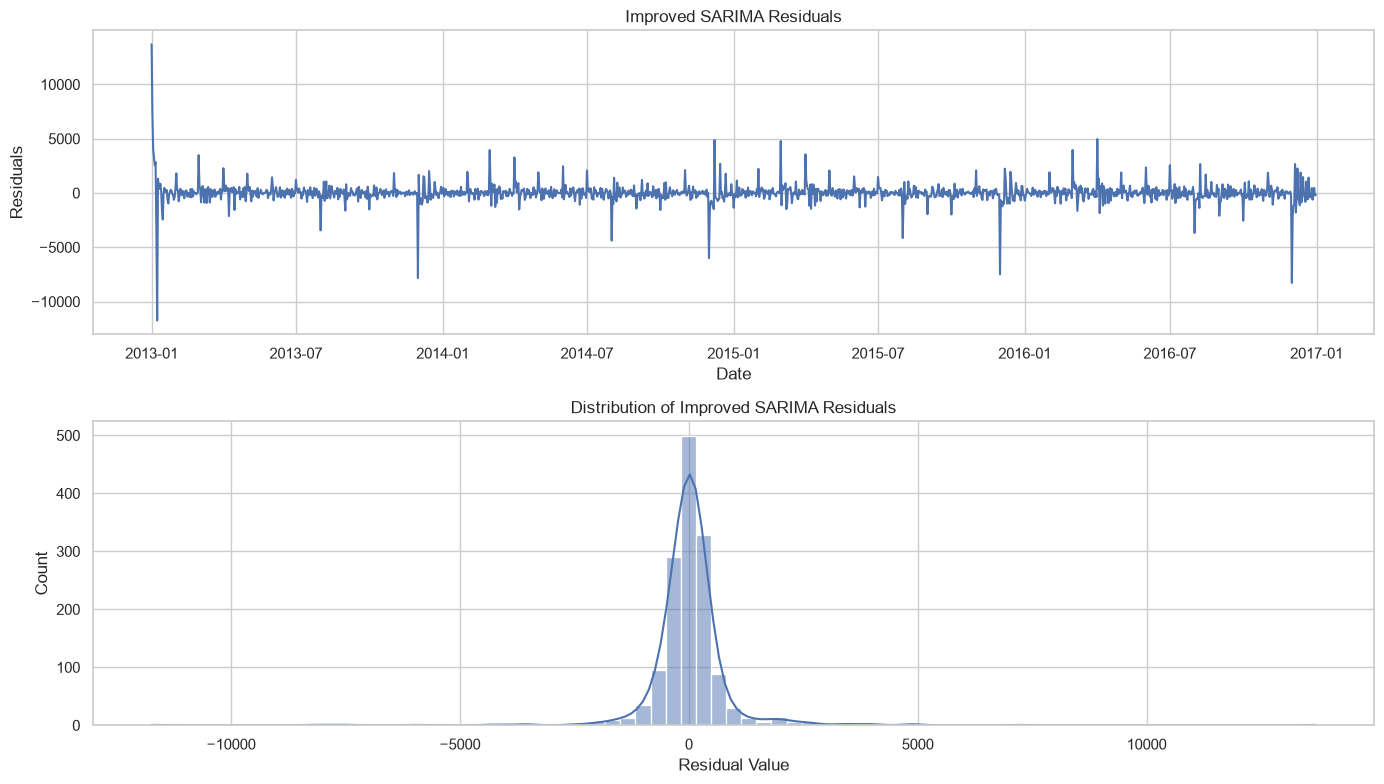

In [28]:
# Extract residuals from improved SARIMA

improved_sarima_residuals = improved_sarima_result.resid

# Plot residuals and their distribution

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(improved_sarima_residuals)
axes[0].set_title("Improved SARIMA Residuals")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Residuals")
axes[0].grid(True)

sns.histplot(
    improved_sarima_residuals,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of Improved SARIMA Residuals")
axes[1].set_xlabel("Residual Value")

plt.tight_layout()
plt.show()

In [29]:
# Test autocorrelation in improved SARIMA residuals

improved_ljung_box_result = acorr_ljungbox(
    improved_sarima_residuals,
    lags=[7, 14, 21, 28],
    return_df=True
)

print("Improved SARIMA - Ljung-Box Test")
print("--------------------------------")

display(improved_ljung_box_result)

Improved SARIMA - Ljung-Box Test
--------------------------------


,lb_stat,lb_pvalue
7,55.799427,1.035025e-09
14,60.474948,9.682903e-08
21,62.379941,5.535813e-06
28,67.450536,4.193050e-05


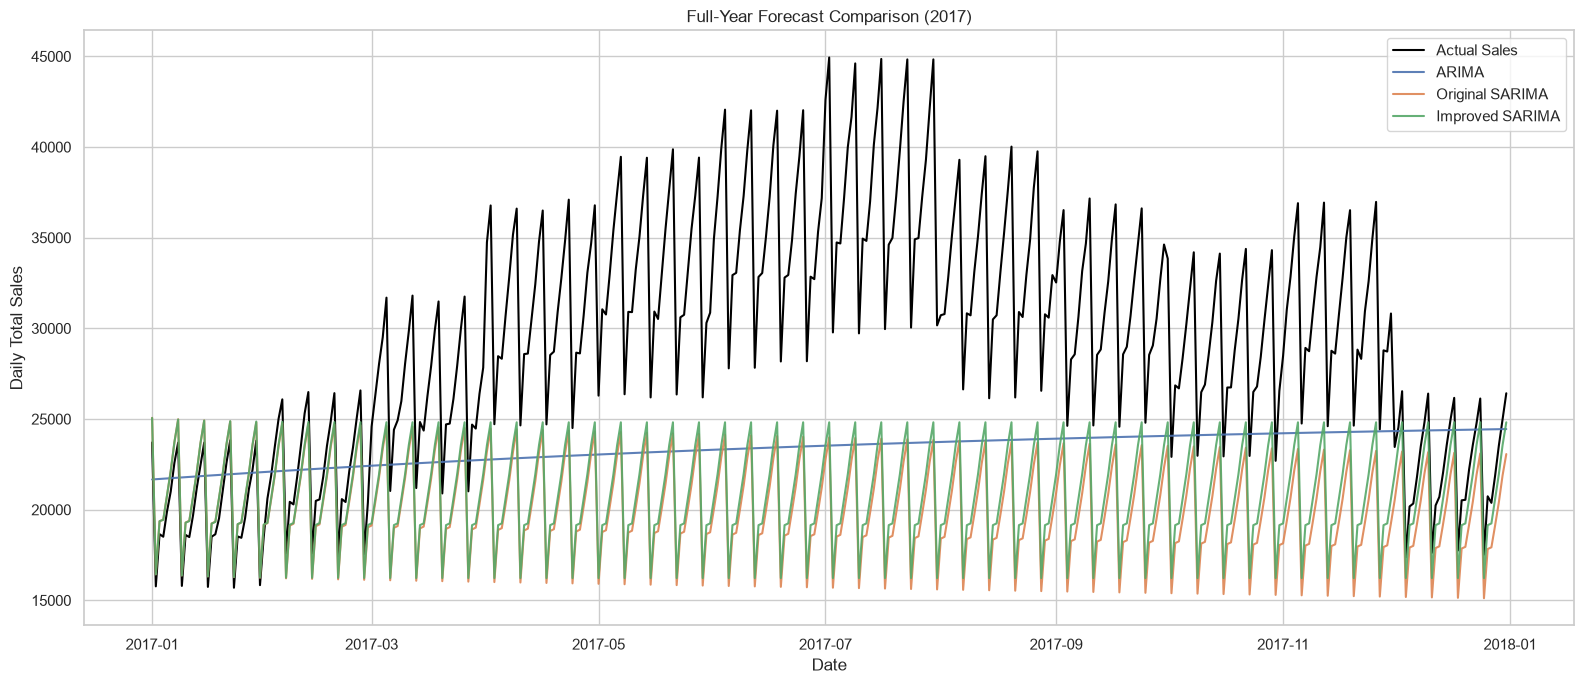

In [30]:
# Actual vs predicted sales for all three models

plt.figure(figsize=(16, 7))

plt.plot(
    test.index,
    test,
    label="Actual Sales",
    color="black",
    linewidth=1.5
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA",
    alpha=0.9
)

plt.plot(
    sarima_forecast.index,
    sarima_forecast,
    label="Original SARIMA",
    alpha=0.9
)

plt.plot(
    improved_sarima_predictions.index,
    improved_sarima_predictions,
    label="Improved SARIMA",
    alpha=0.9
)

plt.title("Full-Year Forecast Comparison (2017)")
plt.xlabel("Date")
plt.ylabel("Daily Total Sales")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()